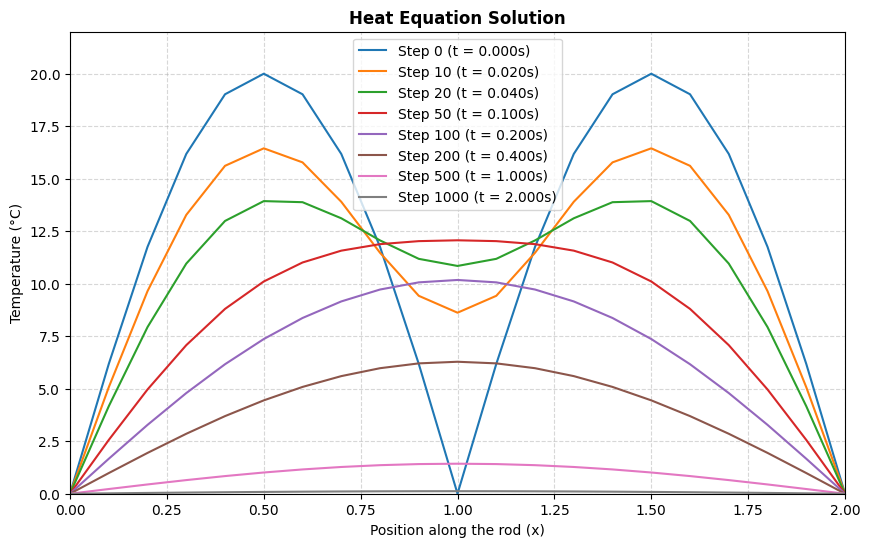

In [5]:
# to solve 1-D heat equation
# initial conditions u(0,t) = 0celsius = u(2,t) ; 0<=t<=4
#u(x,0) = 20 sinpix  ; 0<=x<=2

#PROGRAM STARTS HERE

import numpy as np
import matplotlib.pyplot as plt
import library

L = 2.0  
T = 4.0  
Nx = 20  
Nt = 2000    

dx = L / Nx 
dt = T / Nt 
alpha = dt / (dx**2)  #diffusion parameter

x = np.linspace(0, L, Nx + 1)
u_full = 20.0 * np.abs(np.sin(np.pi * x))
u_full[0] = 0.0
u_full[-1] = 0.0

u_interior_list = [[val] for val in u_full[1:-1]]

N = Nx - 1 
A_list = []
main_diag = (1.0 - 2.0 * alpha) * np.ones(N)
off_diag = alpha * np.ones(N - 1)

A = np.diag(main_diag) + np.diag(off_diag, k=1) + np.diag(off_diag, k=-1)
for i in range(N):
    row = [0.0] * N
    row[i] = 1.0 - 2.0 * alpha  # Main diagonal
    if i > 0:
        row[i - 1] = alpha      # Left element
    if i < N - 1:
        row[i + 1] = alpha      # Right element
    A_list.append(row)

target_steps = [0, 10, 20, 50, 100, 200, 500, 1000]
profiles = {0: u_full.copy()}

for j in range(1, max(target_steps) + 1):
    u_interior_list = library.matrix_multiply(A_list, u_interior_list)

    if j in target_steps:
        u_full_step = np.zeros(Nx + 1)
        u_full_step[1:-1] = [row[0] for row in u_interior_list]
        profiles[j] = u_full_step

plt.figure(figsize=(10, 6))
for step in target_steps:
    plt.plot(x, profiles[step], label=f'Step {step} (t = {step*dt:.3f}s)')

plt.title('Heat Equation Solution', fontsize=12, fontweight='bold')
plt.xlabel('Position along the rod (x)')
plt.ylabel('Temperature (°C)')
plt.xlim(0, L)
plt.ylim(0, 22)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()


#PROGRAM ENDS HERE